# image thresholding

In [17]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
%matplotlib widget

wv = "800nm"
root = f'/Users/yuewang/SLAC/goldthz/Au_data/{wv}/images/'

def hist(img, imgName):
    hist = cv.calcHist([img],[0],None,[256],[0,256])
    plt.figure()
    plt.plot(hist)
    plt.title(imgName)
    plt.xlabel("bins")
    plt.ylabel("# of pixels")
    plt.xlim(0,40)
    plt.show()
    
plt.close('all')

def thresholding(imgName, opts, show=False): # up to 3 options of the threshold limit
    imgPath = os.path.join(root, imgName)
    print(f"image path: {imgPath}")
    img = cv.imread(imgPath, 0)

    if show:
        hist(img, imgName)

    # image mask
    mask = np.zeros(img.shape[:2], dtype="uint8")
    cv.rectangle(mask, (670, 525), (1000, 260), 255, -1)
    cv.imshow("Rectangular Mask", mask)
    masked = cv.bitwise_and(img, img, mask=mask)

    plt.figure(figsize=(9, 5))
    plt.subplot(141)
    plt.imshow(masked, cmap='gray')

    for i in range(len(opts)):
        plt.subplot(1, 4, i+2)
        _, imgThres = cv.threshold(masked, opts[i], 255, cv.THRESH_BINARY)
        plt.imshow(imgThres, cmap='gray')
        plt.title(f"bin {opts[i]}")

    if show:
        plt.show()
    else:
        plt.close()
    return imgThres

imgThres_with = thresholding("07202026_pump_with_window.tiff", [18])
imgThres_no = thresholding("07202026_pump_no_window.tiff", [18])

area_with = cv.countNonZero(imgThres_with)
area_no = cv.countNonZero(imgThres_no)
print(f"with window: {area_with}, no window: {area_no}")
windowRatio = area_with/area_no
print(windowRatio)

image path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/07202026_pump_with_window.tiff
image path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/07202026_pump_no_window.tiff
with window: 12584, no window: 19520
0.644672131147541


# Threshold each image to see how much is blown up

image path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_pre.tiff


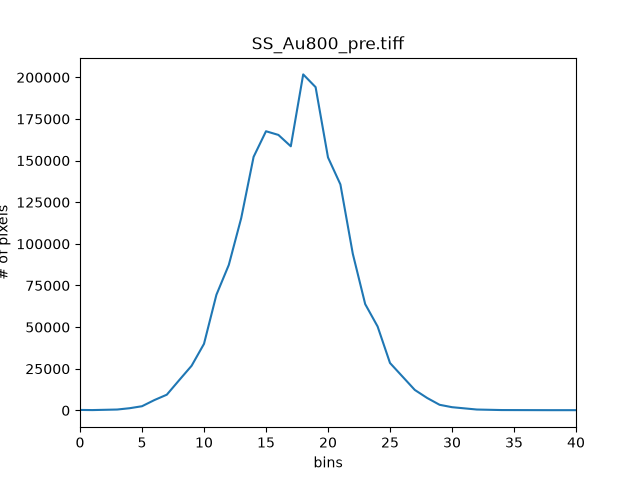

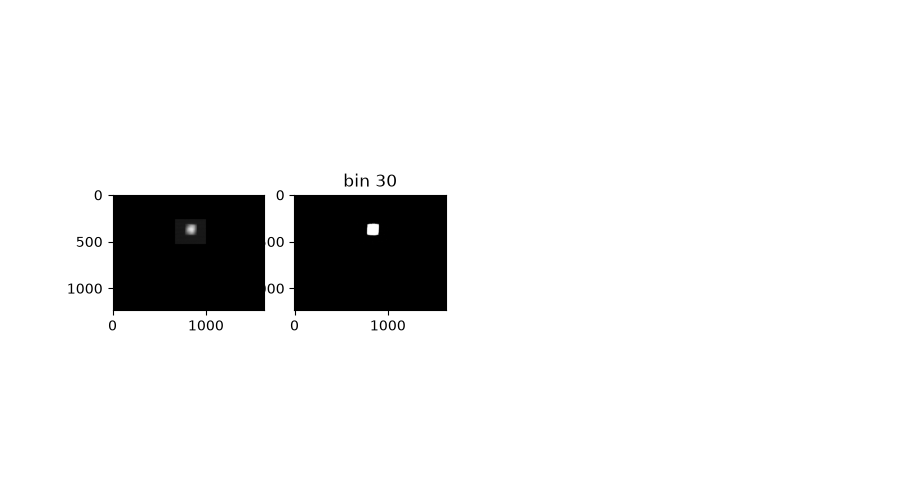

OG window area: 14935
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0001.tiff
image path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0001.tiff
area 14427
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0002.tiff
image path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0002.tiff
area 10026
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0003.tiff


In [19]:
from pprint import pprint

areas = []
def cycle_through(file_root: str, position: str, p_range: list, wp: str, func):
    for digit in p_range:
        pos = position + str(digit)

        shot_num = 3
        for shot in range(shot_num):
            num = '{:0>4}'.format(int(shot + 1))
            imgName = 'SS_Au800_postShot_' + wp + '_' + pos + '_shot' + num + ".tiff" 
            file_path = file_root + imgName

            print("--------------------------------")
            print(f"File path: {file_path}")
            if not os.path.exists(file_path):
                print(f"File path does not exist: {file_path}")
                continue
            else:
                print(f"creating plot for file: {file_path}")
                imgThres = func(imgName, [24], False)
                area = cv.countNonZero(imgThres)
                print("area", area)
                areas.append(area)

preImg = thresholding("SS_Au800_pre.tiff", [30], show=True)
preArea = cv.countNonZero(preImg)
print(f"OG window area: {preArea}")

cycle_through(root, "neg", [i for i in range(3)], wp="wp43", func=thresholding)
cycle_through(root, "pos", [1, 2, 5, '7p5', 10, 12, 15, 20, 25, 30, 50], wp="wp43", func=thresholding)
pprint(areas)
areaMean = np.mean(areas)
areaStd = np.std(areas)
print(f"mean: {areaMean}, std: {areaStd}")



# average ratio of transmitted laser energy U
meanRatio = areaMean/preArea
stdRatio = areaStd/preArea
print(f"For Ratio: mean: {meanRatio}, std: {stdRatio}")


